# t-SNE 데이터 지도 실습

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/v2/ml1/week14/tsne/lab/tsne.ipynb)

고차원에서 가까운 이웃은 지도에서도 이웃으로. 고차원은 정규분포, 지도는 t 분포로 가까움을 재고 KL 발산을 줄인다.

- **파트 1**: 정규분포 vs t 분포 유사도 손 계산, KL 발산
- **파트 2**: 손글씨 숫자 PCA 지도 vs t-SNE 지도, 지도에서 가까운 5개로 맞히기
- **파트 3**: perplexity · 시드 바꾸기, 크기가 다른 두 무리

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요. 파트 2 · 3 은 1 ~ 2분 걸린다.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier

## 파트 1. 두 가지 가까움

한 점에서 이웃 셋까지 거리 1, 2, 3.

In [ ]:
def gaussian_sim(d, sigma=1.0):
    w = np.exp(-d ** 2 / (2 * sigma ** 2))
    return w / w.sum()

def t_sim(d):
    w = None  # TODO: Student t (1 degree of freedom)
    return w / w.sum()

def kl(p, q):
    return None  # TODO: KL(P || Q)

d = np.array([1.0, 2.0, 3.0])
p, q = gaussian_sim(d), t_sim(d)
print("Gaussian:", p.round(3)); print("t       :", q.round(3))
print("KL(P||Q) =", round(kl(p, q), 3))

# How far must the 3rd point be on the map so that its t share matches the Gaussian 0.015?
for far in [3, 5, 10, 20]:
    print(f"3rd point at distance {far:2d} on the map -> t share {t_sim(np.array([1.0, 2.0, far]))[2]:.3f}")

**예상 결과**

```
Gaussian: [0.806 0.18  0.015]
t       : [0.625 0.25  0.125]
KL(P||Q) = 0.114
3rd point at distance  3 on the map -> t share 0.125
3rd point at distance  5 on the map -> t share 0.052
3rd point at distance 10 on the map -> t share 0.014
3rd point at distance 20 on the map -> t share 0.004
```

## 파트 2. 손글씨 숫자 지도

In [ ]:
digits = load_digits()
X, y = digits.data, digits.target

def knn_on_map(Z, y, k=5):
    return cross_val_score(KNeighborsClassifier(k), Z, y, cv=5).mean()

def draw_map(ax, Z, y, title):
    ax.scatter(Z[:, 0], Z[:, 1], c=y, cmap="tab10", s=4)
    for k in range(10):
        ax.text(*np.median(Z[y == k], axis=0), str(k), fontsize=14, weight="bold")
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])

Z_pca = PCA(2).fit_transform(X)
Z_tsne = None  # TODO: 2-D t-SNE map (perplexity 30, init "pca", random_state 0)
fig, axs = plt.subplots(1, 2, figsize=(11, 5))
draw_map(axs[0], Z_pca, y, f"PCA  5-NN {knn_on_map(Z_pca, y):.0%}")
draw_map(axs[1], Z_tsne, y, f"t-SNE  5-NN {knn_on_map(Z_tsne, y):.0%}")
plt.show()

**예상 결과**

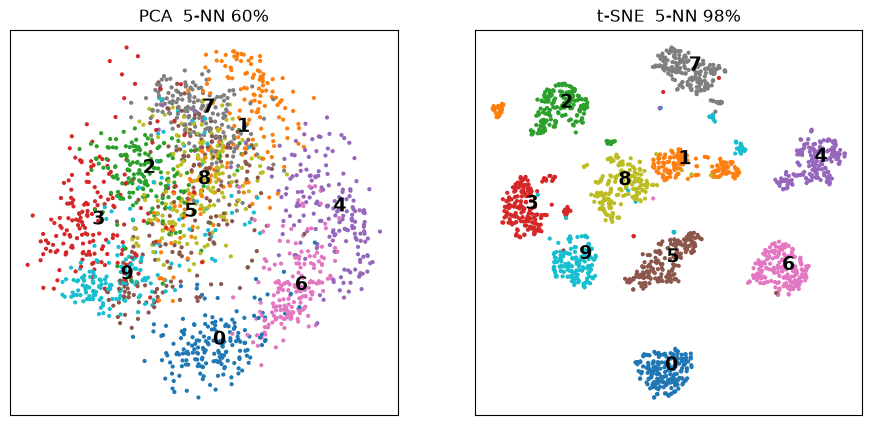

## 파트 3. 설정 · 시드 · 섬의 크기

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(13, 4))
for ax, perp in zip(axs, [5, 30, 100]):
    Z = TSNE(2, perplexity=perp, init="pca", random_state=0).fit_transform(X)
    draw_map(ax, Z, y, f"perplexity {perp}  ({knn_on_map(Z, y):.1%})")
plt.show()

**예상 결과**

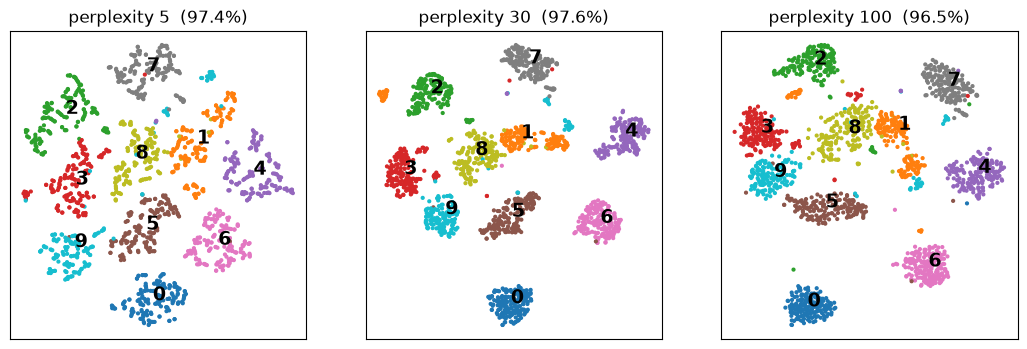

In [ ]:
# Two clusters in 10-D: the gold one is 10x more spread out
rng = np.random.default_rng(0)
A = rng.normal(0, 1, (100, 10))
B = rng.normal(0, 10, (100, 10)); B[:, 0] += 50
C = np.r_[A, B]; label = np.r_[np.zeros(100), np.ones(100)]

def spread(Z):
    return np.sqrt(((Z - Z.mean(axis=0)) ** 2).sum(axis=1).mean())

emb = TSNE(2, perplexity=30, init="pca", random_state=0).fit_transform(C)
print("spread ratio  original:", round(spread(B) / spread(A), 1), "  on the map:", round(spread(emb[label == 1]) / spread(emb[label == 0]), 1))
plt.scatter(*emb[label == 0].T, s=10, label="small cluster"); plt.scatter(*emb[label == 1].T, s=10, label="big cluster")
plt.legend(); plt.gca().set_aspect("equal"); plt.show()

**예상 결과**

```
spread ratio  original: 10.5   on the map: 1.2
```

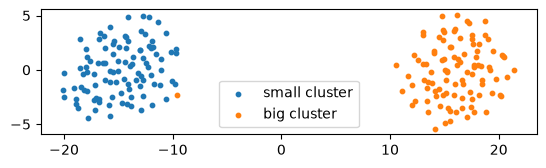

**확인 질문**
1. 파트 1 에서 세 번째 점의 t 몫을 정규분포 몫 (0.015) 만큼 줄이려면 지도에서 얼마나 멀리 둬야 하나?
2. 파트 2 에서 PCA 지도에서도 따로 떨어진 숫자는 무엇인가? t-SNE 에서 서로 붙은 숫자는?
3. 파트 3 에서 `random_state` 만 바꿔 다시 그려 보라. 무엇이 같고 무엇이 다른가?
4. (도전) 파트 3 의 두 무리에서 perplexity 를 5 나 100 으로 바꾸면 지도의 크기 비율은?